In [2]:
#引入出具分析库

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import time

随机抽取9516个用户，针对其行为数据进行研究  
**请注意重新运行时千万不能重复运行，否则运行时间过长，且会覆盖已存在的样本数据**

In [2]:
import pandas as pd
import numpy as np

seed = 42
sample_users = 9512
file_path = '/Users/shenyunzhi/Desktop/淘宝天池项目/UserBehavior.csv'
output_path = '/Users/shenyunzhi/Desktop/淘宝天池项目/sample_9512_users.csv'

# ==================== 第一步：获取所有唯一用户并随机抽取 9512 人 ====================
print("开始读取所有用户ID...")
# 只读取 userid 列，大幅降低内存消耗，加快速度
all_users_df = pd.read_csv(
    file_path, 
    header=None, 
    names=['userid', 'itemid', 'categoryid', 'type', 'timestamp'],
    usecols=['userid']
)
unique_users = all_users_df['userid'].unique()
print(f"总体用户数: {len(unique_users)}")

# 设定随机种子并抽取 9512 个用户
np.random.seed(seed)
sampled_users = np.random.choice(unique_users, size=sample_users, replace=False)

# ==================== 第二步：分块读取，完整保留这 9512 个用户的所有行为 ====================
print("开始读取全量数据并筛选目标用户行为...")
chunks = []
for chunk in pd.read_csv(
    file_path, 
    header=None, 
    names=['userid', 'itemid', 'categoryid', 'type', 'timestamp'],
    chunksize=1_000_000
):
    # 过滤：只保留被抽中用户的全部行为记录
    filtered_chunk = chunk[chunk['userid'].isin(sampled_users)]
    chunks.append(filtered_chunk)

sample_df = pd.concat(chunks, ignore_index=True)

# ==================== 第三步：保存与打印 ====================
sample_df.to_csv(output_path, index=False)
print(f"完成！样本量共 {sample_df.shape[0]} 条行为记录。")
print(f"结果已保存至: {output_path}")

开始读取所有用户ID...
总体用户数: 987994
开始读取全量数据并筛选目标用户行为...
完成！样本量共 962273 条行为记录。
结果已保存至: /Users/shenyunzhi/Desktop/淘宝天池项目/sample_9512_users.csv


共计5列字段，分别是：userid（用户ID）、itemid（商品ID）、categoryid（商品类目ID）、type（行为类型）和timestamp（时间戳）。

In [11]:
# 数据读取
data=pd.read_csv('/Users/shenyunzhi/Desktop/淘宝天池项目/sample_9512_users.csv',index_col=None)
data.columns=['User_Id','Item_Id','Category_Id','Behavior_type','Timestamp']
data.head(5)

,User_Id,Item_Id,Category_Id,Behavior_type,Timestamp
0,1000115,1652876,901282,pv,1511743165
1,1000115,5017410,2459106,pv,1511743217
2,1000115,612209,499642,pv,1511743275
3,1000115,5017410,2459106,pv,1511743411
4,1000115,1907638,2590256,pv,1511743424


In [12]:
data.info()
data.describe()
data["Behavior_type"].value_counts()  #用户行为类型共有四种，分别是：pv、buy、cart和fav。pv表示页面访问，buy表示购买，cart表示加入购物车，fav表示收藏。

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 962273 entries, 0 to 962272
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   User_Id        962273 non-null  int64 
 1   Item_Id        962273 non-null  int64 
 2   Category_Id    962273 non-null  int64 
 3   Behavior_type  962273 non-null  object
 4   Timestamp      962273 non-null  int64 
dtypes: int64(4), object(1)
memory usage: 36.7+ MB


pv      861974
cart     52653
fav      28092
buy      19554
Name: Behavior_type, dtype: int64

In [13]:
# 一、数据读取和数据清洗
# 1.检查空值 ---检查结果发现数据无空值
print(pd.isnull(data["Timestamp"]).value_counts())
print(pd.isnull(data["Item_Id"]).value_counts())
print(pd.isnull(data["User_Id"]).value_counts())

False    962273
Name: Timestamp, dtype: int64
False    962273
Name: Item_Id, dtype: int64
False    962273
Name: User_Id, dtype: int64


In [14]:
# 2.检查和处理异常值
# # 1）判断Timestamp存在负值
# print(data[data["Timestamp"]<0])
# # 2）处理负值
# data=data[data["Timestamp"]>0]
# # 3）检查异常值处理效果
# # 3）检查异常处理结果
# print(data[data["Timestamp"]<0])
print(data["Behavior_type"].value_counts())

pv      861974
cart     52653
fav      28092
buy      19554
Name: Behavior_type, dtype: int64


In [15]:
data['Timestamp'] = pd.to_datetime(data['Timestamp'], unit='s')
data['Date'] = data['Timestamp'].dt.date
data['Time'] = data['Timestamp'].dt.time

In [16]:
# 3. 按照同一个用户 + 同一个商品 + 同一个时间戳判断是否重复，保留第一次出现
data = data.drop_duplicates(subset=['User_Id', 'Item_Id', 'Timestamp'], keep='first')

In [17]:
data.info()
data.describe()
data.head()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 962273 entries, 0 to 962272
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   User_Id        962273 non-null  int64         
 1   Item_Id        962273 non-null  int64         
 2   Category_Id    962273 non-null  int64         
 3   Behavior_type  962273 non-null  object        
 4   Timestamp      962273 non-null  datetime64[ns]
 5   Date           962273 non-null  object        
 6   Time           962273 non-null  object        
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 58.7+ MB


,User_Id,Item_Id,Category_Id,Behavior_type,Timestamp,Date,Time
0,1000115,1652876,901282,pv,2017-11-27 00:39:25,2017-11-27,00:39:25
1,1000115,5017410,2459106,pv,2017-11-27 00:40:17,2017-11-27,00:40:17
2,1000115,612209,499642,pv,2017-11-27 00:41:15,2017-11-27,00:41:15
3,1000115,5017410,2459106,pv,2017-11-27 00:43:31,2017-11-27,00:43:31
4,1000115,1907638,2590256,pv,2017-11-27 00:43:44,2017-11-27,00:43:44


In [18]:
# 只取2017年11月25日至2017年12月3日之间的数据进行研究
# print(data["Date"].value_counts())
data['Date'] = pd.to_datetime(data['Date'])
data=data[(data["Date"]>='2017-11-25')&(data["Date"]<='2017-12-03')]
print(data["Date"].value_counts())

2017-12-02    134210
2017-12-03    114444
2017-12-01    107929
2017-11-25    103348
2017-11-30    101973
2017-11-26    101435
2017-11-29     98978
2017-11-27     94684
2017-11-28     93534
Name: Date, dtype: int64


预处理的数据保存

In [19]:
data.to_csv(r'/Users/shenyunzhi/Desktop/淘宝天池项目/sample_9512_users_cleaned.csv', encoding = 'utf-8', index = False)

In [3]:
data=pd.read_csv("/Users/shenyunzhi/Desktop/淘宝天池项目/sample_9512_users_cleaned.csv",encoding="utf-8")

In [5]:
data['User_Id'].value_counts()

862684    689
134422    671
84647     606
594182    603
848740    595
         ... 
339210      3
479200      2
870700      2
60460       2
96120       2
Name: User_Id, Length: 9512, dtype: int64

In [6]:
import duckdb

# 数据概览：
### 已知用户数是9512，behavior_type有4种，大约100w条行为数据，可以了解一下商品数和品类数

In [ ]:
duckdb.sql("""
           select count(*), count(distinct User_Id) as user_count, count(distinct Item_Id) as item_count, count(distinct Category_Id) as category_count from data
           """).df()
#我们的数据涉及到行数是95w，9512个用户，38w个商品，5788个品类

,count_star(),user_count,item_count,category_count
0,950535,9512,388138,5788


### 用户四大行为占比  
分行为总次数和有此行为用户数两个维度统计，并计算占比

In [23]:
# 粗略统计用户四大行为占比，分行为总次数和有此行为用户数两个维度统计，并计算占比
duckdb.sql("""
        SELECT behavior_type, COUNT(*) AS behavior_count,concat(round(count(*)/sum(count(*)) over (),4)*100,'%') AS behavior_ratio,
        count(distinct User_Id) as behavior_user_count, concat(round(count(distinct User_Id)/sum(count(distinct User_Id)) over (),4)*100,'%') AS behavior_user_ratio
        FROM data group by behavior_type order by behavior_count desc
        """).df()

,Behavior_type,behavior_count,behavior_ratio,behavior_user_count,behavior_user_ratio
0,pv,851273,89.56%,9474,35.35%
1,cart,52123,5.48%,7119,26.56%
2,fav,27735,2.92%,3758,14.02%
3,buy,19404,2.04%,6448,24.060000000000002%


### 根据行为统计，初步观察购买率和收藏加购率  
灰色注释部分为全量数据，代码部分为随机用户抽样数据,发现结果接近

In [39]:
# duckdb.sql("""
# select 672404/984105,(2888255+5530446)/89660670 
# """).df()
duckdb.sql("""
select concat(round(6448/9512,4)*100,'%') as buy_user_rate,concat(round((52123+27735)/851273,4)*100,'%') as fav_add_cart_rate
""").df()

,buy_user_rate,fav_add_cart_rate
0,67.78999999999999%,9.379999999999999%


# 一、时间序列与趋势分析：  
## 1.访客流量分析：
1）pv随时间变化趋势（小时，日）  
2）uv随时间变化趋势（小时，日）  
3）pv/uv随时间变化趋势（小时，日）  
（用python绘制六张趋势折形图）

         Date      pv   DAU      pv_uv
0  2017-11-25  103348  6813  15.169235
1  2017-11-26  101435  6864  14.777826
2  2017-11-27   94684  6829  13.864988
3  2017-11-28   93534  6748  13.860996
4  2017-11-29   98978  6945  14.251692


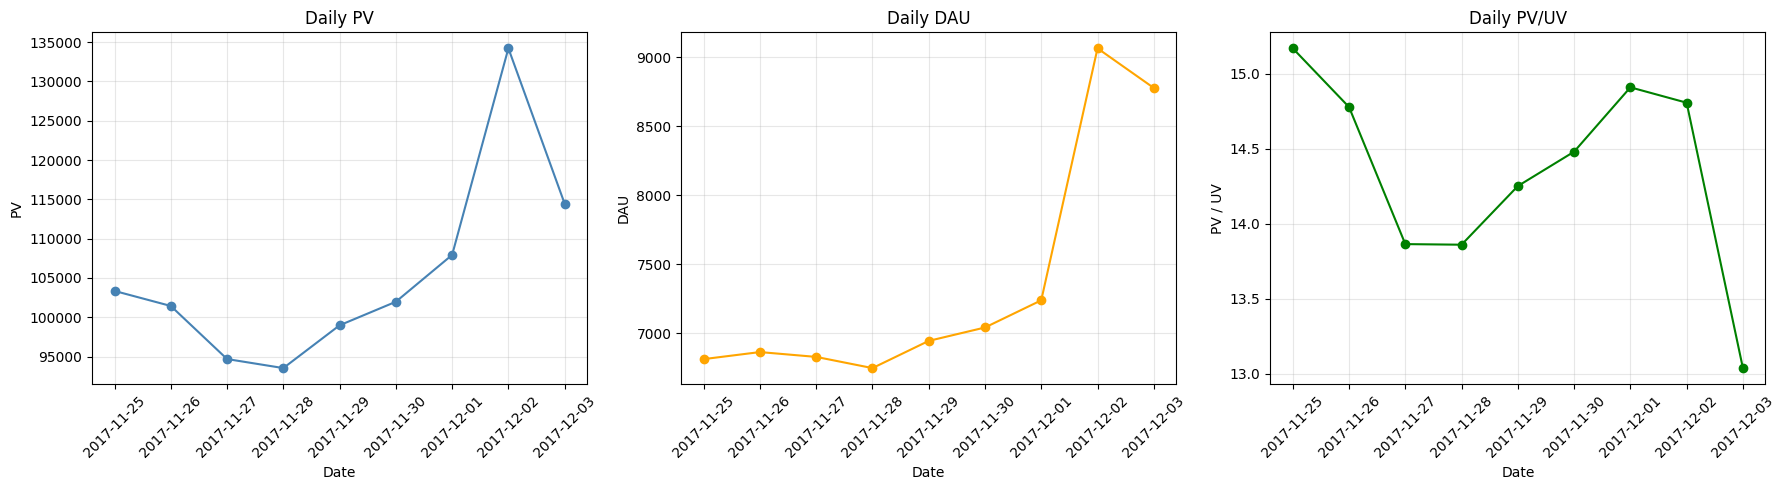

In [ ]:
pv_df = duckdb.sql("""
    select Date, count(User_Id) as pv
    from data
    group by Date
    order by Date 
""").df()

dau_df = duckdb.sql("""
    select Date, count(DISTINCT User_Id) as DAU
    from data
    group by Date
    order by Date
""").df()

pv_uv_df = duckdb.sql("""
    select Date,
           count(User_Id) * 1.0 / count(DISTINCT User_Id) as pv_uv
    from data
    group by Date
    order by Date
""").df()

trend = pv_df.merge(dau_df, on='Date', how='outer').merge(pv_uv_df, on='Date', how='outer') #pv为基础表，DAU和PV/UV合并到pv_df中
trend = trend.sort_values('Date')# 按日期排序

print(trend.head())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 左图：PV
axes[0].plot(trend['Date'], trend['pv'], marker='o', color='steelblue')
axes[0].set_title('Daily PV')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('PV')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.3)

# 中图：DAU
axes[1].plot(trend['Date'], trend['DAU'], marker='o', color='orange')
axes[1].set_title('Daily DAU')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('DAU')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(alpha=0.3)

# 右图：PV/UV
axes[2].plot(trend['Date'], trend['pv_uv'], marker='o', color='green')
axes[2].set_title('Daily PV/UV')
axes[2].set_xlabel('Date')
axes[2].set_ylabel('PV / UV')
axes[2].tick_params(axis='x', rotation=45)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# duckdb.sql("""
#            select avg(pv_uv) as avg_pv_uv from trend
#            """).df() # daily avg(pv/uv ) = 14.35

insights：  
1.可以看出，大促期间，访问流量（不论是访问人次pv还是访问用户数uv）在12/1到12/2日猛增，都出现了明显的峰值  
2.daily avg(pv/uv ) = 14.35 ，说明在大促期间，人均访问次数为14.35次，且也在大促预热11/25，和12/1到12/2日这两阶段达到峰值

   Hour     pv   DAU     pv_uv
0     0  32448  4318  7.514590
1     1  39665  4966  7.987314
2     2  47541  5577  8.524476
3     3  44502  5614  7.926968
4     4  46095  5761  8.001215


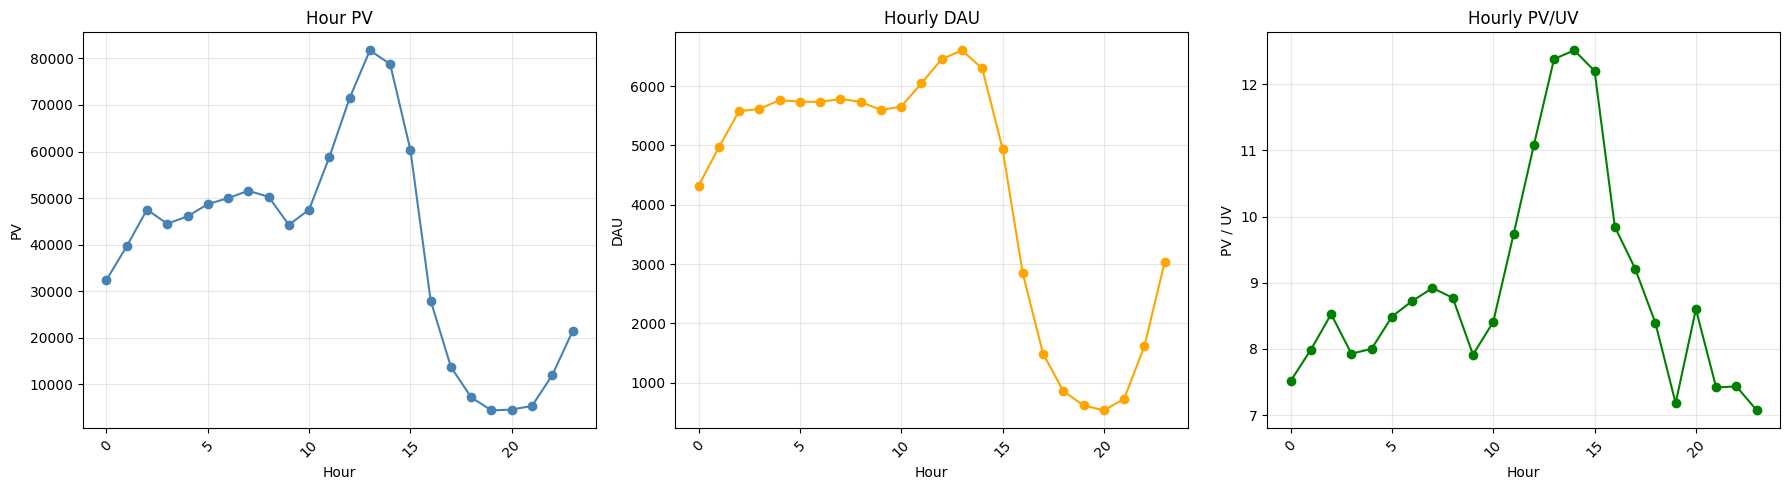

In [ ]:
#其次以小时为单位统计日内流量，新导入数据是精确到秒的太慢转换到小时
data['Hour'] = pd.to_datetime(data['Time'].astype(str)).dt.hour
pv_df = duckdb.sql("""
    select Hour , count(User_Id) as pv
    from data
    group by Hour
    order by Hour
""").df()

dau_df = duckdb.sql("""
    select Hour, count(DISTINCT User_Id) as DAU
    from data
    group by Hour
    order by Hour
""").df()

pv_uv_df = duckdb.sql("""
    select Hour,        
           count(User_Id) * 1.0 / count(DISTINCT User_Id) as pv_uv
    from data
    group by Hour
    order by Hour               
""").df()

trend = pv_df.merge(dau_df, on='Hour', how='outer').merge(pv_uv_df, on='Hour', how='outer')
trend = trend.sort_values('Hour')# 按日期排序

print(trend.head())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 左图：PV
axes[0].plot(trend['Hour'], trend['pv'], marker='o', color='steelblue')
axes[0].set_title('Hour PV')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('PV')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.3)

# 中图：DAU
axes[1].plot(trend['Hour'], trend['DAU'], marker='o', color='orange')   
axes[1].set_title('Hourly DAU')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('DAU')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(alpha=0.3)

# 右图：PV/UV
axes[2].plot(trend['Hour'], trend['pv_uv'], marker='o', color='green')
axes[2].set_title('Hourly PV/UV')
axes[2].set_xlabel('Hour')  
axes[2].set_ylabel('PV / UV')
axes[2].tick_params(axis='x', rotation=45)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

conclusion：  
从日内的流量趋势看，用户倾向于中午12点左右逛逛淘宝，下午访问量快速滑落，猜测用户在学习工作，晚上睡觉前用户也会再看看淘宝，访问流量回升

## 2.时间序列之成交量趋势变化（天，小时）  
注意点： 
1.如果有价格信息，实际上还应该统计成交额  
2.成交量可以分购买总次数和购买人数两个维度统计  

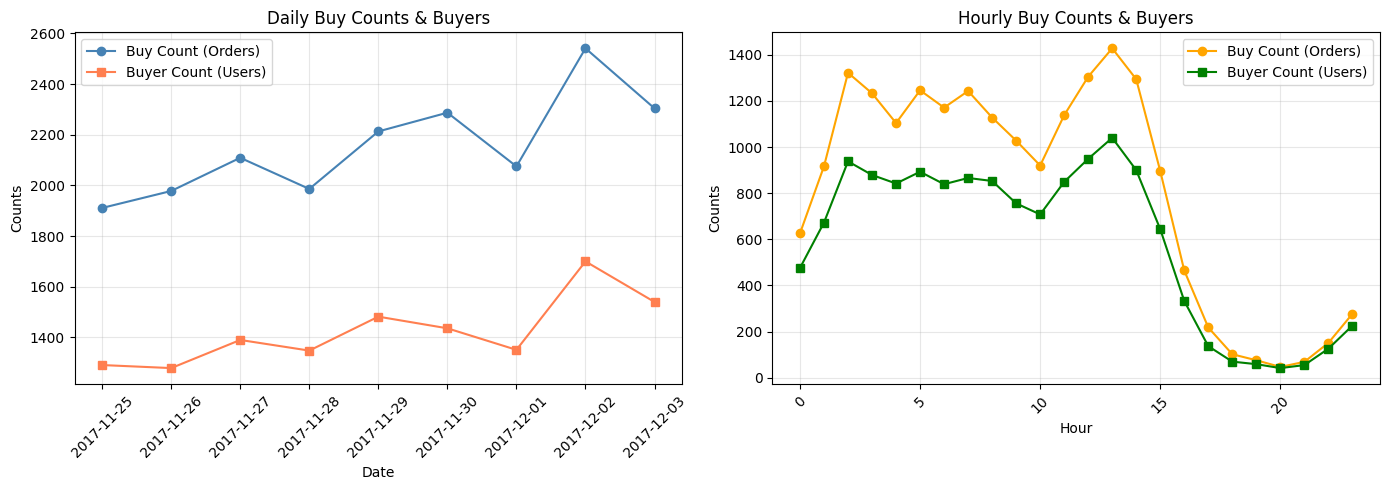

In [ ]:
buy_order_counts = duckdb.sql("""
           select Date, count(*) as buy_count_daily,count(distinct User_id) as buyer_count_daily from data 
           where Behavior_type = 'buy' 
           group by Date order by Date
           """).df()
buy_order_hour_counts = duckdb.sql("""
           select Hour, count(*) as buy_count_hour,count(distinct User_id) as buyer_count_hour from data 
           where Behavior_type = 'buy' 
           group by Hour order by Hour
           """).df()

fig,axes = plt.subplots(1, 2, figsize=(14, 5))
# ================= 左图：按天统计 =================
# 第一条线：购买次数
axes[0].plot(buy_order_counts['Date'], buy_order_counts['buy_count_daily'], 
             marker='o', color='steelblue', label='Buy Count (Orders)')
# 第二条线：购买人数
axes[0].plot(buy_order_counts['Date'], buy_order_counts['buyer_count_daily'], 
             marker='s', color='coral', label='Buyer Count (Users)')

axes[0].set_title('Daily Buy Counts & Buyers')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Counts')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.3)
axes[0].legend()  # 显示图例

# ================= 右图：按小时统计 =================
# 第一条线：购买次数
axes[1].plot(buy_order_hour_counts['Hour'], buy_order_hour_counts['buy_count_hour'], 
             marker='o', color='orange', label='Buy Count (Orders)') #添加label
# 第二条线：购买人数
axes[1].plot(buy_order_hour_counts['Hour'], buy_order_hour_counts['buyer_count_hour'], 
             marker='s', color='green', label='Buyer Count (Users)')

axes[1].set_title('Hourly Buy Counts & Buyers')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('Counts')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(alpha=0.3)
axes[1].legend()  # 显示图例

plt.tight_layout()
plt.show()


**insights：**  
1.购买趋势与上文的流量趋势基本相同，但是更为平稳，说明大部分用户还是反复浏览对比商品之后购买    
2.不论是天还是小时的时间精度，购买次数与购买人数完全正相关    
3.日内，用户一般在中午12点左右购买商品，且有可能购买多笔订单；晚上八点前后，购买用户减少，且每个用户大概率只购买一笔  
4.在大促期间，在12/1到12/2日购买商品的用户人数增加，且购买次数也增加

## 3.用户其他行为（如点击、收藏、加购等）随时间变化趋势

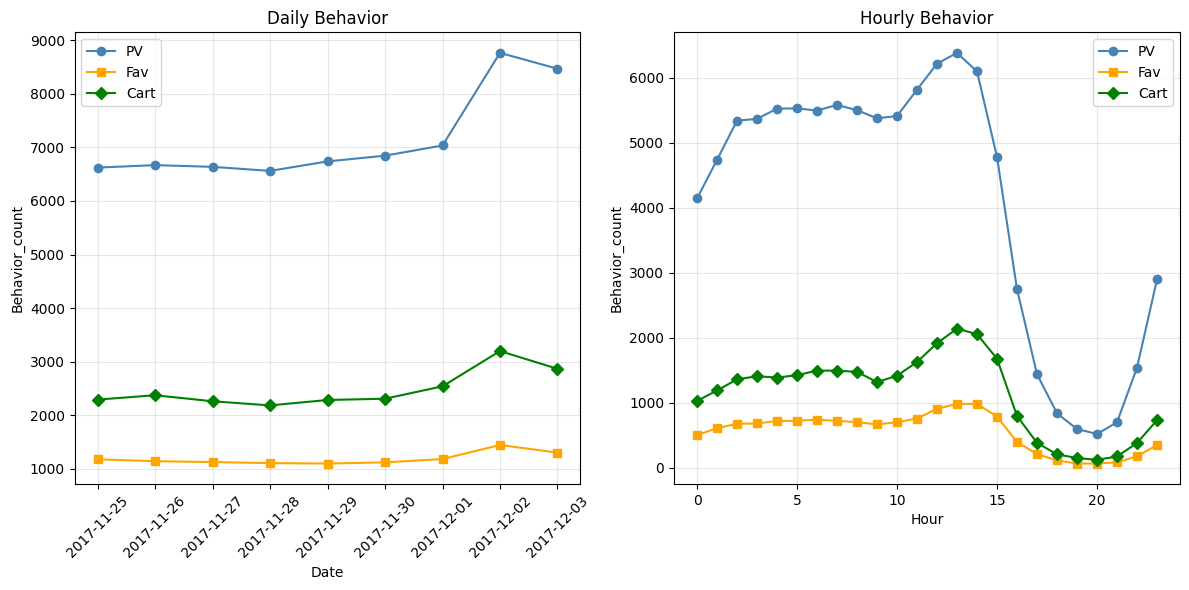

In [47]:
#统计不同行为的人数
behavior_Date_count = duckdb.sql("""
           select Date,count(distinct case when behavior_type='pv' then User_Id end) as pv_count,
           count(distinct case when behavior_type='fav' then User_Id end) as fav_count,
           count(distinct case when behavior_type='cart' then User_Id end) as cart_count
           from data group by Date order by Date    
           """).df()
behavior_Hour_count = duckdb.sql("""
           select Hour,count(distinct case when behavior_type='pv' then User_Id end) as pv_count,
           count(distinct case when behavior_type='fav' then User_Id end) as fav_count,
           count(distinct case when behavior_type='cart' then User_Id end) as cart_count
           from data group by Hour order by Hour
           """).df()
# #统计不同行为的次数
# behavior_Date_count = duckdb.sql("""
#            select Date,count(case when behavior_type='pv' then 1 end) as pv_count,
#            count(case when behavior_type='fav' then 1 end) as fav_count,
#            count(case when behavior_type='cart' then 1 end) as cart_count
#            from data group by Date order by Date    
#            """).df()
# behavior_Hour_count = duckdb.sql("""
#            select Hour,count(case when behavior_type='pv' then 1 end) as pv_count,
#            count(case when behavior_type='fav' then 1 end) as fav_count,
#            count(case when behavior_type='cart' then 1 end) as cart_count
#            from data group by Hour order by Hour
#            """).df()
fig,axes=plt.subplots(1,2,figsize=(12,6))
# 左图：按天统计
axes[0].plot(behavior_Date_count['Date'], behavior_Date_count['pv_count'], marker='o', color='steelblue', label='PV')
axes[0].plot(behavior_Date_count['Date'], behavior_Date_count['fav_count'], marker='s', color='orange', label='Fav')
axes[0].plot(behavior_Date_count['Date'], behavior_Date_count['cart_count'], marker='D', color='green', label='Cart')
axes[0].set_title('Daily Behavior')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Behavior_count')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.3)
axes[0].legend()
# 右图：按小时统计
axes[1].plot(behavior_Hour_count['Hour'], behavior_Hour_count['pv_count'], marker='o', color='steelblue', label='PV')
axes[1].plot(behavior_Hour_count['Hour'], behavior_Hour_count['fav_count'], marker='s', color='orange', label='Fav')
axes[1].plot(behavior_Hour_count['Hour'], behavior_Hour_count['cart_count'], marker='D', color='green', label='Cart')
axes[1].set_title('Hourly Behavior')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('Behavior_count')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. 大促预热和火爆阶段，用户热门访问品类
1) 12/1到12/2日，增量访客都访问的是什么品类的商品，统计top10品类
2) 12/1到12/2日，新增的购买用户都买的是什么品类的商品，统计top10品类
3) #10点到12点，增量访客都访问的是什么品类的商品，统计top10品类

In [ ]:
### 不加coalesce的后果：某个品类昨天是0，今天突然爆火到1万，你的代码会把它直接丢掉（因为差值是 NULL）
### lag窗口函数分区只能有category_id，不能有date，否则每一天都会变成一个独立的分区。此分区里，只有当天的一行数据，没有“上一行”
top10_pv_1201_1202 = duckdb.sql("""
                        With Daily_Visitor_Cate as (
                        select Date,Category_id,count(distinct case when behavior_type='pv' then user_id end) as pv_count,
                        (count(distinct case when behavior_type='pv' then user_id end)-COALESCE(lag(count(distinct case when behavior_type='pv' then user_id end),1) over(partition by Category_id order by Date),0))  as pv_count_diff
                        from data group by Date,Category_id order by Date,Category_id)
                        select Category_id,pv_count_diff from Daily_Visitor_Cate 
                        where Date = '2017-12-02' order by pv_count_diff desc limit 10
                    """).df()
top10_buy_1201_1202 = duckdb.sql("""
                        With Daily_buyer_Cate as (
                        select Date,Category_id,count(distinct case when behavior_type='buy' then user_id end) as buy_count,
                        (count(distinct case when behavior_type='buy' then user_id end)-COALESCE(lag(count(distinct case when behavior_type='buy' then user_id end),1) over(partition by Category_id order by Date),0))  as buy_count_diff
                        from data group by Date,Category_id order by Date,Category_id)
                        select Category_id,buy_count_diff from Daily_buyer_Cate 
                        where Date = '2017-12-02' order by buy_count_diff desc limit 10
                    """).df()
#以日为统计精度时，我们只需要看12/2日的top10品类即可，用到的是limit 10
#而以小时为统计精度时，我们只需要看10点到12点的top10品类，不能用limit，必须用窗口函数rank
#在第一个 CTE Hourly_Visitor_Cate 里算好了 LAG，在第二个 CTE Hourly_Visitor_Cate1 才做 WHERE Hour between 11 and 12。
#where过滤不影响lag计算
top10_pv_10_12am= duckdb.sql("""
                        With Hourly_Visitor_Cate as (
                        select Hour,Category_id,count(distinct case when behavior_type='pv' then user_id end) as pv_count,
                        (count(distinct case when behavior_type='pv' then user_id end)-COALESCE(lag(count(distinct case when behavior_type='pv' then user_id end),1) over(partition by Category_id order by Hour),0))  as pv_count_diff
                        from data group by Hour,Category_id order by Hour,Category_id),
                        Hourly_Visitor_Cate1 as (select Hour,Category_id,pv_count_diff,rank() over (partition by Hour order by pv_count_diff desc) as rank from Hourly_Visitor_Cate 
                        where Hour between 11 and 12 order by Hour)
                        select Hour,Category_id,pv_count_diff,rank from Hourly_Visitor_Cate1 where rank <= 10
                        """).df()

## 用户转化率（pv->cart->fav->buy）分析
**1. 整体转化率(以用户+商品id为明细级别统计行为)**  
**2. 分不同购买路径统计转化率 难点！**

In [33]:
#我在纠结是否需要去重，以及是以用户为明细级别统计还是以用户+商品id为明细级别统计
behavior_counts = duckdb.sql("""
           select User_Id,Item_Id,Behavior_type, count(*) as counts from data 
           group by User_Id,Item_Id,Behavior_type 
           order by User_Id,Item_Id,Behavior_type asc,counts desc
           """).df().pivot(index=['User_Id','Item_Id'],columns='Behavior_type',values='counts').reset_index() #必须重置索引不然User_Id和Item_Id会变成索引
#最好用sum over窗口函数统计一下四种行为占比
duckdb.sql("""
           select concat(round(count(*)/count(*),4)*100,'%') as access_ratio,
           concat(round(count(pv)/count(*),4)*100,'%') as pv_ratio,
           concat(round(count(fav)/count(*),4)*100,'%') as fav_ratio,
           concat(round(count(cart)/count(*),4)*100,'%') as cart_ratio, 
           concat(round(count(buy)/count(*),3)*100,'%') as buy_ratio
           from behavior_counts
""").df()

,access_ratio,pv_ratio,fav_ratio,cart_ratio,buy_ratio
0,100.0%,93.53%,3.81%,7.04%,2.6%


因为需要事先学习一下机器学习部分的代码，所以先开展用户购买预测分析

In [2]:
#因为数据量还是很大，机器学习太慢，这里用前100000条数据学习
data2 = pd.read_csv('sample_20m_cleaned.csv', nrows=100000)

In [3]:
#机器学习模型（包括随机森林）的输入必须是**数值**，不能直接吃字符串。`.map()` 是最基础的**类别编码**手段。
data2['行为类型'] = data2['Behavior_type'].map({'pv':1, 'cart':2, 'fav':3, 'buy':5})
#讲明细数据转化为用户级别数据
#第1步：把每个行为数字转成单字符列表
data2['行为类型1'] = data2['行为类型'].apply(lambda x: list(str(x)))
#第2步：时间戳也转换成字符列表（这里的转换其实是有问题的），但是实际上这里没有用到时间特征，之后用到的时候需要修改
data2['时间戳1'] = data2['Timestamp'].apply(lambda x: list(str(x)))
# 第3步：按用户分组，把行为列表和时间列表拼接起来
behavior = data2.groupby('User_Id')['行为类型1'].sum()
time = data2.groupby('User_Id')['时间戳1'].sum()
data2 = pd.DataFrame({ 'behavior_list': behavior, '时间戳_list': time})

**6 个特征映射汇总**：

| 特征名 | 含义 | 类型 |
| --- | --- | --- |
| `is_pv` | 点击次数 | 计数 |
| `is_cart` | 是否加购过 | 0/1 |
| `is_fav` | 是否收藏过 | 0/1 |
| `Behavior_list_len` | 总行为数 | 计数 |
| `fav_much` | 收藏次数 | 计数 |
| `cart_much` | 加购次数 | 计数 |

In [4]:
from collections import Counter as Count
#第4步：添加特征列：是否购买加购收藏以及各自的次数
#点击次数
data2['is_pv'] = data2['behavior_list'].apply(lambda x: Count(x)['1'])
#是否加购
data2['is_cart'] = data2['behavior_list'].apply(lambda x: 1 if '2' in x else 0)
#是否购买
data2['is_buy'] = data2['behavior_list'].apply(lambda x: 1 if '5' in x else 0)
# 是否收藏
data2['is_fav'] = data2['behavior_list'].apply(lambda x: 1 if '3' in x else 0)
# 总行为数
data2['behavior_list_len'] = data2['behavior_list'].apply(lambda x: len(x))
# 收藏次数和加购次数
data2['fav_much']  = data2['behavior_list'].apply(lambda x: Count(x)['3'])
data2['cart_much'] = data2['behavior_list'].apply(lambda x: Count(x)['2'])

In [5]:
data2.head(10)


,behavior_list,时间戳_list,is_pv,is_cart,is_buy,is_fav,behavior_list_len,fav_much,cart_much
User_Id,,,,,,,,,
4,"[1, 1]","[2, 0, 1, 7, -, 1, 1, -, 2, 8, , 1, 1, :, 0, ...",2,0,0,0,2,0,0
11,[1],"[2, 0, 1, 7, -, 1, 2, -, 0, 2, , 1, 3, :, 5, ...",1,0,0,0,1,0,0
21,[1],"[2, 0, 1, 7, -, 1, 1, -, 2, 6, , 0, 2, :, 5, ...",1,0,0,0,1,0,0
30,[1],"[2, 0, 1, 7, -, 1, 1, -, 2, 5, , 1, 5, :, 3, ...",1,0,0,0,1,0,0
41,"[1, 1]","[2, 0, 1, 7, -, 1, 1, -, 2, 8, , 0, 5, :, 1, ...",2,0,0,0,2,0,0
61,[1],"[2, 0, 1, 7, -, 1, 2, -, 0, 2, , 0, 7, :, 0, ...",1,0,0,0,1,0,0
68,[1],"[2, 0, 1, 7, -, 1, 1, -, 3, 0, , 0, 5, :, 1, ...",1,0,0,0,1,0,0
78,[1],"[2, 0, 1, 7, -, 1, 1, -, 2, 9, , 0, 0, :, 2, ...",1,0,0,0,1,0,0
88,[1],"[2, 0, 1, 7, -, 1, 2, -, 0, 3, , 0, 6, :, 1, ...",1,0,0,0,1,0,0


In [6]:
#第5步：添加预测的标签列
data2['label'] = data2['is_buy'].astype(int)
del data2['is_buy']
print(data2.shape)

(91886, 9)


In [ ]:
# #第六步：EDA & 缺失值检查，这一步因为内核崩溃了就没运行
# #画出每列的缺失值情况，白色横条 = 缺失。这里应该是全黑
# msno.matrix(data2, labels=True)   
# #方图 + 核密度估计（KDE），看分布形状
# f, ax = plt.subplots(1, 2, figsize=(12, 5))
# sns.distplot(data2['fav_much'], bins=30, kde=True, ax=ax[0])   # 收藏次数分布
# sns.distplot(data2['cart_much'], bins=30, kde=True, ax=ax[1])  # 加购次数分布

# data2.index = list(range(data2.shape[0]))  # 把索引重置为 0,1,2,...


: 

In [7]:
#第7步：训练集&测试集划分
# train_test_split：本文主角，用来划分训练/测试集。
# StratifiedKFold：分层 K 折交叉验证（后面会讲）。
# cross_val_score：一步完成交叉验证的评分。
# RandomForestClassifier：随机森林分类器（模型本体）。
# accuracy_score：计算准确率（预测对的比例）。
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

drop = ['time_list', 'behavior_list', 'label', 'time_list_len','时间戳_list']
train_col = [x for x in data2.columns if x not in drop]
labels = data2['label']

X_train, X_test, Y_train, Y_test = train_test_split(
    data2[train_col], data2['label'], test_size=0.20, random_state=42, stratify=data2['label'] 
)
print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)
print(train_col)
# X_train: (73508, 6)  X_test: (18378, 6)

(73508, 6) (18378, 6) (73508,) (18378,)
['is_pv', 'is_cart', 'is_fav', 'behavior_list_len', 'fav_much', 'cart_much']


In [8]:
#第8步：调参的随机森林
rfc = RandomForestClassifier(n_estimators=1000, max_depth=5,max_features='sqrt')
rfc.fit(X_train, Y_train)
y_pred = rfc.predict(X_test)
print('Model accuracy score : {0:0.4f}'.format(accuracy_score(Y_test, y_pred)))
#model accuracy score : 0.9996

Model accuracy score : 0.9996


In [ ]:
#第9步：GridSearchCV网格搜索调参 ，大概运行13分钟
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(max_features='auto', oob_score=True, random_state=1, n_jobs=-1)

param_grid = {
    "min_samples_leaf": [1, 5, 10],
    "max_depth": [4, 5, 6],
    "n_estimators": [100, 500, 1000, 1500]
}

gs = GridSearchCV(estimator=rf, param_grid=param_grid,
                  scoring='accuracy', cv=5, n_jobs=-1)
gs = gs.fit(X_train, Y_train)


In [10]:
print(gs.best_score_)
print(gs.best_params_)

0.9997823360609702
{'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 100}


In [12]:
#模块九：五折交叉验证和指标评估
forest = RandomForestClassifier(max_depth=6, min_samples_leaf=1, n_estimators=100)

def muti_score(model):
    accuracy  = cross_val_score(model, X_train, Y_train, scoring='accuracy',  cv=5)
    precision = cross_val_score(model, X_train, Y_train, scoring='precision', cv=5)
    recall    = cross_val_score(model, X_train, Y_train, scoring='recall',    cv=5)
    f1_score  = cross_val_score(model, X_train, Y_train, scoring='f1',        cv=5)
    auc       = cross_val_score(model, X_train, Y_train, scoring='roc_auc',   cv=5)
    print("准确率：", accuracy.mean())
    print("精确率：", precision.mean())
    print("召回率：", recall.mean())
    print("F1_score：", f1_score.mean())
    print("AUC：", auc.mean())

muti_score(forest)

准确率： 0.9998775630511098
精确率： 1.0
召回率： 0.9901878013545712
F1_score： 0.9969258997415974
AUC： 0.9999113577161662
